# Segbench

In [6]:
from pathlib import Path

In [7]:
# Gather the dataset.
root = Path("data_semantics/training")
images = sorted((root / "image_2").glob("*.png"))
dataset = [(img, root / "semantic_rgb" / img.name) for img in images]

print(f"{len(dataset)=}")

len(dataset)=200


In [8]:
dataset[0]

(PosixPath('data_semantics/training/image_2/000000_10.png'),
 PosixPath('data_semantics/training/semantic_rgb/000000_10.png'))

In [9]:
import time

import numpy as np
import pandas as pd
import torch
from PIL import Image
from transformers import (
    AutoImageProcessor,
    AutoModelForSemanticSegmentation,
    AutoModelForUniversalSegmentation,
)

device = "cuda" if torch.cuda.is_available() else "cpu"
CAR_RGB = (0, 0, 142)  # Cityscapes color for "car".

models = {
    "nvidia/segformer-b0-finetuned-cityscapes-1024-1024": AutoModelForSemanticSegmentation,
    "nvidia/segformer-b2-finetuned-cityscapes-1024-1024": AutoModelForSemanticSegmentation,
    "nvidia/segformer-b5-finetuned-cityscapes-1024-1024": AutoModelForSemanticSegmentation,
    "facebook/mask2former-swin-tiny-cityscapes-semantic": AutoModelForUniversalSegmentation,
    "facebook/mask2former-swin-large-cityscapes-semantic": AutoModelForUniversalSegmentation,
}


def sync():
    if device == "cuda":
        torch.cuda.synchronize()


def evaluate(name, model_cls):
    processor = AutoImageProcessor.from_pretrained(name)
    model = model_cls.from_pretrained(name).to(device).eval()
    car = model.config.label2id["car"]

    inter = union = gt_total = 0
    times = []
    for img_path, label_path in dataset:
        img = Image.open(img_path).convert("RGB")
        gt = (np.array(Image.open(label_path).convert("RGB")) == CAR_RGB).all(-1)
        inputs = processor(images=img, return_tensors="pt").to(device)

        sync()
        start = time.perf_counter()
        with torch.no_grad():
            outputs = model(**inputs)
        sync()
        times.append(time.perf_counter() - start)

        pred = processor.post_process_semantic_segmentation(
            outputs, target_sizes=[img.size[::-1]]
        )[0].cpu().numpy() == car
        inter += (pred & gt).sum()
        union += (pred | gt).sum()
        gt_total += gt.sum()

    return {
        "model": name.split("/")[-1],
        "car_iou": inter / union,
        "car_recall": inter / gt_total,
        "ms_per_img": 1000 * np.mean(times[1:]),  # Skip warm-up.
    }


results = pd.DataFrame([evaluate(name, cls) for name, cls in models.items()])
results

preprocessor_config.json:   0%|          | 0.00/272 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 15.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

...

model.safetensors: reconstructing file:   0%|          |  0.00B /  866MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-cityscapes-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the c

,model,car_iou,car_recall,ms_per_img
0,segformer-b0-finetuned-cityscapes-1024-1024,0.803514,0.901583,16.313478
1,segformer-b2-finetuned-cityscapes-1024-1024,0.841457,0.940812,58.017369
2,segformer-b5-finetuned-cityscapes-1024-1024,0.889356,0.959548,751.143358
3,mask2former-swin-tiny-cityscapes-semantic,0.816679,0.921872,75.135318
4,mask2former-swin-large-cityscapes-semantic,0.853191,0.940584,174.158132


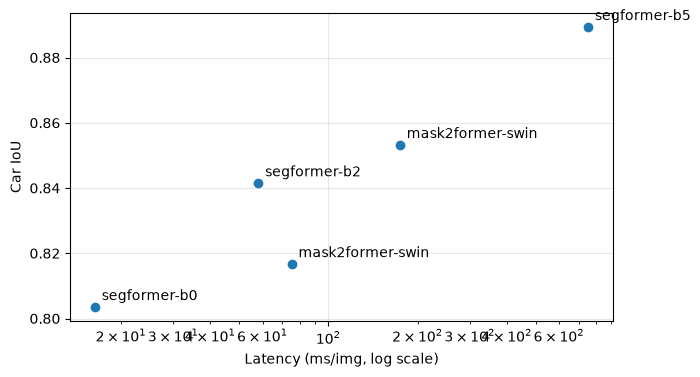

In [10]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(results["ms_per_img"], results["car_iou"])
for _, row in results.iterrows():
    ax.annotate(row["model"].split("-")[0] + "-" + row["model"].split("-")[1],
                (row["ms_per_img"], row["car_iou"]),
                textcoords="offset points", xytext=(5, 5))
ax.set_xscale("log")
ax.set_xlabel("Latency (ms/img, log scale)")
ax.set_ylabel("Car IoU")
ax.grid(True, alpha=0.3)
plt.show()

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/554 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-tiny-cityscapes-semantic
Key                                                                                                                                | Status     | 
-----------------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0, 1, 2, 3, 4, 5}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                               | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params 

Loading weights:   0%|          | 0/758 [00:00<?, ?it/s]

[transformers] Mask2FormerForUniversalSegmentation LOAD REPORT from: facebook/mask2former-swin-large-cityscapes-semantic
Key                                                                                                                      | Status     | 
-------------------------------------------------------------------------------------------------------------------------+------------+-
model.pixel_level_module.encoder.swin.encoder.layers.{0, 1, 2, 3}.blocks.{0...17}.attention.self.relative_position_index | UNEXPECTED | 
model.pixel_level_module.encoder.swin.layernorm.bias                                                                     | MISSING    | 
model.pixel_level_module.encoder.swin.layernorm.weight                                                                   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the c

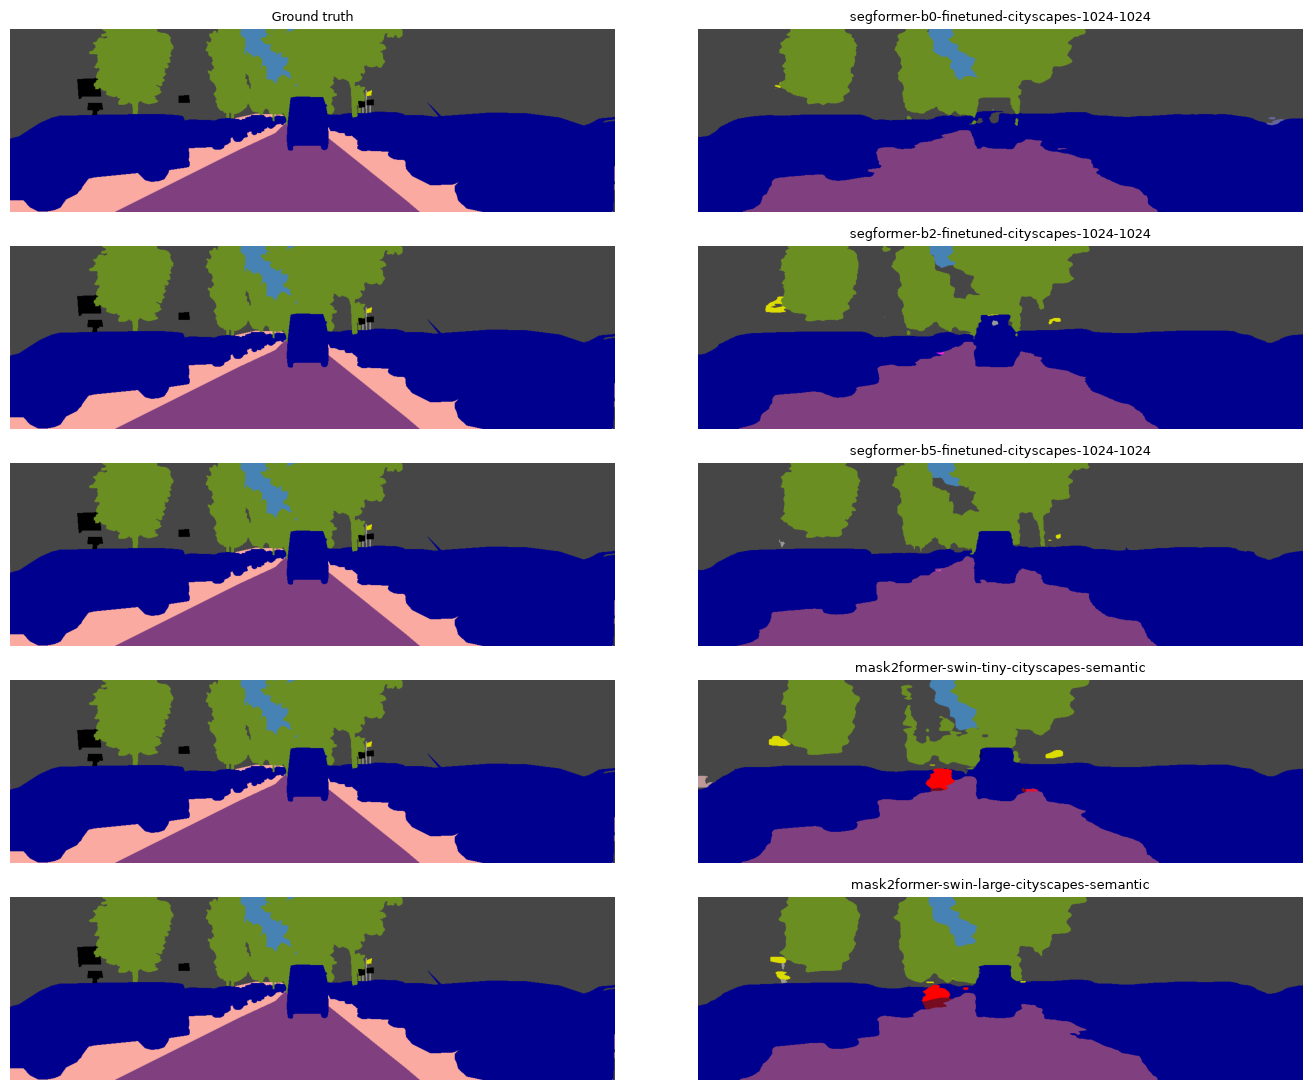

In [11]:
# Cityscapes palette, indexed by train ID (car = 13).
PALETTE = np.array([
    (128, 64, 128), (244, 35, 232), (70, 70, 70), (102, 102, 156), (190, 153, 153),
    (153, 153, 153), (250, 170, 30), (220, 220, 0), (107, 142, 35), (152, 251, 152),
    (70, 130, 180), (220, 20, 60), (255, 0, 0), (0, 0, 142), (0, 0, 70),
    (0, 60, 100), (0, 80, 100), (0, 0, 230), (119, 11, 32),
], dtype=np.uint8)

img_path, label_path = dataset[5]
img = Image.open(img_path).convert("RGB")
gt = Image.open(label_path).convert("RGB")

fig, axes = plt.subplots(len(models), 2, figsize=(14, 2.2 * len(models)))
for row, (name, model_cls) in zip(axes, models.items()):
    processor = AutoImageProcessor.from_pretrained(name)
    model = model_cls.from_pretrained(name).to(device).eval()
    inputs = processor(images=img, return_tensors="pt").to(device)
    with torch.no_grad():
        outputs = model(**inputs)
    pred = processor.post_process_semantic_segmentation(
        outputs, target_sizes=[img.size[::-1]]
    )[0].cpu().numpy()

    row[0].imshow(gt)
    row[1].imshow(PALETTE[pred])
    row[1].set_title(name.split("/")[-1], fontsize=9)
    for ax in row:
        ax.axis("off")

axes[0, 0].set_title("Ground truth", fontsize=9)
plt.tight_layout()
plt.show()